# E6 — Cross-representation and background consistency

## Scientific question

**Which conclusions about the phage-lytic space remain stable when the negative background and the representation are changed?**

E6 is an **integration and consistency stage**. It does not redo E2–E5, does not generate new embeddings,
and does not introduce redundancy thresholds. Redundancy sensitivity belongs to **E7**.

## Representations

E6 compares five frozen representation spaces:

### Explicit sequence-derived spaces
- `E2_all` — composition / sequence-complexity descriptors
- `E3_all` — physicochemical descriptors
- `E2_E3_all` — combined explicit descriptor space

### Learned latent spaces
- `ESM2-T6`
- `ESM2-T30`

The three explicit spaces use standardized Euclidean geometry, matching the logic of E4.
The two PLM spaces use cosine geometry, matching E5_v2.

Because the distance metrics differ by representation family, E6 focuses primarily on:

1. **within-representation ordering of negative backgrounds**, and
2. **dimensionless local-neighborhood purity/enrichment**, which is directly interpretable across spaces.

## Negative-background contrasts

All five representations are evaluated on the same paired balanced samples for:

- `P_core vs N_easy`
- `P_core vs N_hard`
- `P_core vs N_mixed`

`N_mixed` is sampled from the pooled `N_easy ∪ N_hard` population without artificially balancing the
two negative strata internally.

The same `P_core` sample is reused across all three contrasts within each repeat, and the same sequence IDs
are used across all five representations.

## Quantitative outputs

For each representation/background contrast:

- binary silhouette in the native representation metric;
- macro same-label kNN fraction at `k=25`;
- P-core same-label kNN fraction;
- negative-background same-label kNN fraction;
- local enrichment relative to the balanced binary expectation of 0.5.

## Cross-representation consistency

E6 does **not** test whether representation geometries are point-by-point equivalent.

Instead it asks whether the biological ordering of backgrounds is stable across representation spaces.
The primary consistency object is the rank order of `N_easy`, `N_hard`, and `N_mixed` by:

- silhouette;
- macro same-label neighborhood purity.

Pairwise representation agreement is therefore defined as agreement in background ordering, not direct
distance correlation.

## Functional-subtype consistency

E6 also harmonizes already-frozen E4 and E5_v2 results for Endolysin / DPO / VAL to determine whether:

- local same-subtype coherence;
- relative subtype heterogeneity;

show the same qualitative ordering across explicit and learned representations.

No new subtype geometry is calculated here.

## Main outputs

- `background_sensitivity.tsv`
- `background_sensitivity_repeats.tsv`
- `background_rankings.tsv`
- `cross_representation_consistency.tsv`
- `geometry_agreement.tsv`
- `representation_specific_patterns.tsv`
- `subtype_consistency.tsv`
- `subtype_pattern_summary.tsv`
- `E6_metadata.json`

All outputs are written to:

`EDA_results/E6/`

In [1]:
from pathlib import Path
import json
import itertools
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import pyarrow as pa
import pyarrow.parquet as pq

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

from IPython.display import display


sns.set_theme(
    context="notebook",
    style="ticks",
    font_scale=1.0,
)

pd.set_option("display.max_columns", 180)
pd.set_option("display.width", 220)


RANDOM_SEED = 42

BACKGROUND_REPEATS = 5
N_PER_CLASS = 1_500
K = 25
SILHOUETTE_SAMPLE_SIZE = 1_500

# E6 intentionally does not touch sequence redundancy.
REDUNDANCY_ANALYSIS_DISABLED = True

# E6 consumes already-computed PLM embeddings only.
EMBEDDING_GENERATION_DISABLED = True

## 1. Paths and frozen inputs

In [2]:
cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "EDA" else cwd

E0_PATH = (
    PROJECT_ROOT
    / "EDA_results"
    / "E0"
    / "phagelytic_eda_universe.csv"
)

E2_PARQUET = (
    PROJECT_ROOT
    / "EDA_results"
    / "E2"
    / "roxy_sequence_composition.parquet"
)

E3_PARQUET = (
    PROJECT_ROOT
    / "EDA_results"
    / "E3"
    / "physicochemical_descriptors.parquet"
)

E4_DIR = PROJECT_ROOT / "EDA_results" / "E4"
E5_DIR = PROJECT_ROOT / "EDA_results" / "E5_v2"

E4_FEATURE_SETS_PATH = (
    E4_DIR
    / "roxy_geometry_feature_sets.tsv"
)

E4_GEOMETRY_PATH = (
    E4_DIR
    / "roxy_geometry_summary.tsv"
)

E4_NEIGHBORHOODS_PATH = (
    E4_DIR
    / "roxy_neighborhoods.tsv"
)

E5_BIOLOGICAL_PATH = (
    E5_DIR
    / "cross_embedding_biological_summary.tsv"
)

E5_NEIGHBORHOOD_PATH = (
    E5_DIR
    / "cross_embedding_neighborhood_summary.tsv"
)


EMBED_ROOT = (
    PROJECT_ROOT
    / "data"
    / "representations"
    / "sylphy_embeddings"
    / "models"
)

PLM_REPRESENTATIONS = {
    "esm2_t6": {
        "display_name": "ESM2-T6",
        "family": "learned",
        "distance_metric": "cosine",
        "slug": "facebook_esm2_t6_8m_ur50d",
        "expected_dimensions": 320,
    },
    "esm2_t30": {
        "display_name": "ESM2-T30",
        "family": "learned",
        "distance_metric": "cosine",
        "slug": "facebook_esm2_t30_150m_ur50d",
        "expected_dimensions": 640,
    },
}

for rep, cfg in PLM_REPRESENTATIONS.items():
    cfg["parquet"] = (
        EMBED_ROOT
        / cfg["slug"]
        / "embeddings_last_mean_fp32.parquet"
    )
    cfg["metadata"] = (
        EMBED_ROOT
        / cfg["slug"]
        / "metadata.json"
    )


RESULT_DIR = PROJECT_ROOT / "EDA_results" / "E6"
FIGURE_DIR = RESULT_DIR / "figures"

RESULT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


BACKGROUND_REPEATS_PATH = (
    RESULT_DIR
    / "background_sensitivity_repeats.tsv"
)

BACKGROUND_SUMMARY_PATH = (
    RESULT_DIR
    / "background_sensitivity.tsv"
)

BACKGROUND_RANKINGS_PATH = (
    RESULT_DIR
    / "background_rankings.tsv"
)

CONSISTENCY_PATH = (
    RESULT_DIR
    / "cross_representation_consistency.tsv"
)

GEOMETRY_AGREEMENT_PATH = (
    RESULT_DIR
    / "geometry_agreement.tsv"
)

REP_SPECIFIC_PATH = (
    RESULT_DIR
    / "representation_specific_patterns.tsv"
)

SUBTYPE_CONSISTENCY_PATH = (
    RESULT_DIR
    / "subtype_consistency.tsv"
)

SUBTYPE_PATTERN_PATH = (
    RESULT_DIR
    / "subtype_pattern_summary.tsv"
)

SAMPLE_MANIFEST_PATH = (
    RESULT_DIR
    / "background_sample_manifest.tsv"
)

METADATA_PATH = (
    RESULT_DIR
    / "E6_metadata.json"
)


required_files = [
    E0_PATH,
    E2_PARQUET,
    E3_PARQUET,
    E4_FEATURE_SETS_PATH,
    E4_GEOMETRY_PATH,
    E4_NEIGHBORHOODS_PATH,
    E5_BIOLOGICAL_PATH,
    E5_NEIGHBORHOOD_PATH,
]

for path in required_files:
    if not path.is_file():
        raise FileNotFoundError(
            f"Required frozen input not found: {path}"
        )

for rep, cfg in PLM_REPRESENTATIONS.items():
    if not cfg["parquet"].is_file():
        raise FileNotFoundError(
            f"Frozen embedding parquet not found for {rep}: "
            f"{cfg['parquet']}"
        )

    if not cfg["metadata"].is_file():
        raise FileNotFoundError(
            f"Frozen embedding metadata not found for {rep}: "
            f"{cfg['metadata']}"
        )


print(f"Project root : {PROJECT_ROOT}")
print(f"E6 results   : {RESULT_DIR}")

Project root : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass
E6 results   : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E6


## 2. Freeze the five E6 representation spaces

In [3]:
feature_sets = pd.read_csv(
    E4_FEATURE_SETS_PATH,
    sep="\t",
)

E2_FEATURES = (
    feature_sets.loc[
        feature_sets[
            "feature_set"
        ].eq("E2_all"),
        "feature",
    ]
    .astype(str)
    .tolist()
)

E3_FEATURES = (
    feature_sets.loc[
        feature_sets[
            "feature_set"
        ].eq("E3_all"),
        "feature",
    ]
    .astype(str)
    .tolist()
)

if len(E2_FEATURES) != 71:
    raise RuntimeError(
        f"Expected 71 E2 geometry features, found {len(E2_FEATURES)}."
    )

if len(E3_FEATURES) != 27:
    raise RuntimeError(
        f"Expected 27 E3 geometry features, found {len(E3_FEATURES)}."
    )

if set(E2_FEATURES) & set(E3_FEATURES):
    raise RuntimeError(
        "Unexpected feature-name overlap between E2_all and E3_all."
    )


REPRESENTATIONS = {
    "E2_all": {
        "display_name": "E2 composition",
        "family": "explicit",
        "distance_metric": "euclidean",
        "feature_count": len(E2_FEATURES),
    },
    "E3_all": {
        "display_name": "E3 physicochemical",
        "family": "explicit",
        "distance_metric": "euclidean",
        "feature_count": len(E3_FEATURES),
    },
    "E2_E3_all": {
        "display_name": "E2+E3 combined",
        "family": "explicit",
        "distance_metric": "euclidean",
        "feature_count": len(E2_FEATURES) + len(E3_FEATURES),
    },
}

for rep, cfg in PLM_REPRESENTATIONS.items():
    REPRESENTATIONS[rep] = {
        "display_name": cfg["display_name"],
        "family": cfg["family"],
        "distance_metric": cfg["distance_metric"],
        "feature_count": cfg["expected_dimensions"],
    }


representation_manifest = pd.DataFrame(
    [
        {
            "representation": rep,
            **cfg,
        }
        for rep, cfg in REPRESENTATIONS.items()
    ]
)

display(representation_manifest)

,representation,display_name,family,distance_metric,feature_count
0,E2_all,E2 composition,explicit,euclidean,71
1,E3_all,E3 physicochemical,explicit,euclidean,27
2,E2_E3_all,E2+E3 combined,explicit,euclidean,98
3,esm2_t6,ESM2-T6,learned,cosine,320
4,esm2_t30,ESM2-T30,learned,cosine,640


## 3. Recover the exact common universe and labels

In [4]:
def load_uid_column(parquet_path):
    out = pd.read_parquet(
        parquet_path,
        columns=["sequence_uid"],
    )

    out["sequence_uid"] = (
        out["sequence_uid"]
        .astype(str)
    )

    if out["sequence_uid"].duplicated().any():
        raise RuntimeError(
            f"Duplicate sequence_uid values in {parquet_path}"
        )

    return out


t6_uids = load_uid_column(
    PLM_REPRESENTATIONS[
        "esm2_t6"
    ]["parquet"]
)

t30_uids = load_uid_column(
    PLM_REPRESENTATIONS[
        "esm2_t30"
    ]["parquet"]
)

common_uid_set = set(
    t6_uids["sequence_uid"]
)

if set(
    t30_uids["sequence_uid"]
) != common_uid_set:
    raise RuntimeError(
        "T6 and T30 embedding universes are not identical."
    )

if len(common_uid_set) != 434_768:
    raise RuntimeError(
        f"Unexpected common embedding universe: {len(common_uid_set):,}"
    )


e0 = pd.read_csv(
    E0_PATH,
    usecols=[
        "sequence_uid",
        "sequence_state",
        "clean_subtype",
    ],
    dtype={
        "sequence_uid": str,
        "sequence_state": str,
        "clean_subtype": str,
    },
    low_memory=False,
)

if len(e0) != 442_329:
    raise RuntimeError(
        f"Unexpected E0 row count: {len(e0):,}"
    )

if not e0["sequence_uid"].is_unique:
    raise RuntimeError(
        "E0 sequence_uid is not unique."
    )


common_labels = e0.loc[
    e0["sequence_uid"].isin(
        common_uid_set
    )
].copy()

if len(common_labels) != 434_768:
    raise RuntimeError(
        "Common PLM universe did not map one-to-one to E0."
    )


common_labels["binary_label"] = pd.Series(
    pd.NA,
    index=common_labels.index,
    dtype="string",
)

common_labels.loc[
    common_labels[
        "sequence_state"
    ].eq("P_core"),
    "binary_label",
] = "P_core"

common_labels.loc[
    common_labels[
        "sequence_state"
    ].isin(
        ["N_easy", "N_hard"]
    ),
    "binary_label",
] = "N_mixed"


print(
    f"Common E6 universe: {len(common_labels):,}"
)

display(
    common_labels[
        "sequence_state"
    ]
    .value_counts()
    .rename("n")
    .to_frame()
)

Common E6 universe: 434,768


,n
sequence_state,
U_explicit,227256
U_other_unresolved,128181
N_easy,53867
P_core,11259
challenge_ambiguous_structural,9613
N_hard,4322
challenge_lytic_related,270


## 4. Freeze paired background samples

In [5]:
rng_master = np.random.default_rng(
    RANDOM_SEED
)

P_POOL = (
    common_labels.loc[
        common_labels[
            "sequence_state"
        ].eq("P_core"),
        "sequence_uid",
    ]
    .astype(str)
    .to_numpy()
)

N_EASY_POOL = (
    common_labels.loc[
        common_labels[
            "sequence_state"
        ].eq("N_easy"),
        "sequence_uid",
    ]
    .astype(str)
    .to_numpy()
)

N_HARD_POOL = (
    common_labels.loc[
        common_labels[
            "sequence_state"
        ].eq("N_hard"),
        "sequence_uid",
    ]
    .astype(str)
    .to_numpy()
)

N_MIXED_POOL = (
    common_labels.loc[
        common_labels[
            "sequence_state"
        ].isin(
            ["N_easy", "N_hard"]
        ),
        "sequence_uid",
    ]
    .astype(str)
    .to_numpy()
)


for name, pool in [
    ("P_core", P_POOL),
    ("N_easy", N_EASY_POOL),
    ("N_hard", N_HARD_POOL),
    ("N_mixed", N_MIXED_POOL),
]:
    if len(pool) < N_PER_CLASS:
        raise RuntimeError(
            f"{name}: insufficient sequences for E6 sampling."
        )


BACKGROUND_POOLS = {
    "N_easy": N_EASY_POOL,
    "N_hard": N_HARD_POOL,
    "N_mixed": N_MIXED_POOL,
}


SAMPLE_PLANS = {}
manifest_rows = []

for repeat in range(
    BACKGROUND_REPEATS
):
    rng = np.random.default_rng(
        RANDOM_SEED
        + repeat * 10_003
    )

    p_uids = rng.choice(
        P_POOL,
        size=N_PER_CLASS,
        replace=False,
    )

    for background, pool in BACKGROUND_POOLS.items():
        neg_uids = rng.choice(
            pool,
            size=N_PER_CLASS,
            replace=False,
        )

        contrast = (
            f"P_core_vs_{background}"
        )

        SAMPLE_PLANS[
            (
                contrast,
                repeat,
            )
        ] = {
            "P_core": p_uids.tolist(),
            "negative": neg_uids.tolist(),
        }

        for uid in p_uids:
            manifest_rows.append(
                {
                    "contrast": contrast,
                    "background": background,
                    "repeat": repeat,
                    "analysis_group": "P_core",
                    "sequence_uid": str(uid),
                }
            )

        for uid in neg_uids:
            manifest_rows.append(
                {
                    "contrast": contrast,
                    "background": background,
                    "repeat": repeat,
                    "analysis_group": "negative",
                    "sequence_uid": str(uid),
                }
            )


sample_manifest = pd.DataFrame(
    manifest_rows
)

sample_manifest.to_csv(
    SAMPLE_MANIFEST_PATH,
    sep="\t",
    index=False,
)


REQUIRED_SAMPLE_UIDS = set(
    sample_manifest[
        "sequence_uid"
    ]
)

print(
    f"Unique sequences required for E6 background metrics: "
    f"{len(REQUIRED_SAMPLE_UIDS):,}"
)

print()
display(
    sample_manifest.groupby(
        [
            "contrast",
            "repeat",
            "analysis_group",
        ]
    )
    .size()
    .rename("n")
    .reset_index()
    .head(18)
)

Unique sequences required for E6 background metrics: 22,332



,contrast,repeat,analysis_group,n
0,P_core_vs_N_easy,0,P_core,1500
1,P_core_vs_N_easy,0,negative,1500
2,P_core_vs_N_easy,1,P_core,1500
3,P_core_vs_N_easy,1,negative,1500
4,P_core_vs_N_easy,2,P_core,1500
5,P_core_vs_N_easy,2,negative,1500
6,P_core_vs_N_easy,3,P_core,1500
7,P_core_vs_N_easy,3,negative,1500
8,P_core_vs_N_easy,4,P_core,1500
9,P_core_vs_N_easy,4,negative,1500


## 5. Stream, standardize, and extract explicit descriptor spaces

In [6]:
def parquet_feature_columns(
    parquet_path,
    requested_features,
):
    pf = pq.ParquetFile(
        parquet_path
    )

    missing = (
        set(requested_features)
        - set(
            pf.schema_arrow.names
        )
    )

    if missing:
        raise RuntimeError(
            f"{parquet_path.name}: missing requested features: "
            f"{sorted(missing)[:10]}"
        )

    if "sequence_uid" not in pf.schema_arrow.names:
        raise RuntimeError(
            f"{parquet_path.name}: sequence_uid missing."
        )

    return pf


def fit_scaler_on_common_universe(
    parquet_path,
    feature_columns,
    common_uids,
    batch_size=10_000,
):
    pf = parquet_feature_columns(
        parquet_path,
        feature_columns,
    )

    scaler = StandardScaler()

    n_seen = 0

    for batch in pf.iter_batches(
        batch_size=batch_size,
        columns=[
            "sequence_uid"
        ] + feature_columns,
    ):
        frame = batch.to_pandas()

        frame["sequence_uid"] = (
            frame["sequence_uid"]
            .astype(str)
        )

        mask = frame[
            "sequence_uid"
        ].isin(
            common_uids
        )

        if not mask.any():
            continue

        x = frame.loc[
            mask,
            feature_columns,
        ].to_numpy(
            dtype=np.float64,
            copy=True,
        )

        if not np.isfinite(x).all():
            raise RuntimeError(
                f"Non-finite descriptor values detected in {parquet_path.name}."
            )

        scaler.partial_fit(x)

        n_seen += len(x)

    if n_seen != len(common_uids):
        raise RuntimeError(
            f"{parquet_path.name}: scaler saw {n_seen:,} common rows; "
            f"expected {len(common_uids):,}."
        )

    return scaler


def extract_descriptor_sample(
    parquet_path,
    feature_columns,
    selected_uids,
    batch_size=10_000,
):
    pf = parquet_feature_columns(
        parquet_path,
        feature_columns,
    )

    selected_uids = set(
        str(uid)
        for uid in selected_uids
    )

    pieces = []

    for batch in pf.iter_batches(
        batch_size=batch_size,
        columns=[
            "sequence_uid"
        ] + feature_columns,
    ):
        frame = batch.to_pandas()

        frame["sequence_uid"] = (
            frame["sequence_uid"]
            .astype(str)
        )

        mask = frame[
            "sequence_uid"
        ].isin(
            selected_uids
        )

        if mask.any():
            pieces.append(
                frame.loc[
                    mask
                ].copy()
            )

    if not pieces:
        raise RuntimeError(
            f"No requested descriptor rows extracted from {parquet_path.name}."
        )

    out = pd.concat(
        pieces,
        ignore_index=True,
    )

    if out[
        "sequence_uid"
    ].duplicated().any():
        raise RuntimeError(
            f"{parquet_path.name}: duplicate sequence_uid after extraction."
        )

    missing = (
        selected_uids
        - set(
            out["sequence_uid"]
        )
    )

    if missing:
        raise RuntimeError(
            f"{parquet_path.name}: missed {len(missing)} requested sequence_uid values."
        )

    return out


print("Fitting E2 scaler on the common PLM universe...")
E2_SCALER = fit_scaler_on_common_universe(
    E2_PARQUET,
    E2_FEATURES,
    common_uid_set,
)

print("Fitting E3 scaler on the common PLM universe...")
E3_SCALER = fit_scaler_on_common_universe(
    E3_PARQUET,
    E3_FEATURES,
    common_uid_set,
)


e2_sample = extract_descriptor_sample(
    E2_PARQUET,
    E2_FEATURES,
    REQUIRED_SAMPLE_UIDS,
)

e3_sample = extract_descriptor_sample(
    E3_PARQUET,
    E3_FEATURES,
    REQUIRED_SAMPLE_UIDS,
)


e2_sample = e2_sample.sort_values(
    "sequence_uid"
).reset_index(drop=True)

e3_sample = e3_sample.sort_values(
    "sequence_uid"
).reset_index(drop=True)


if not e2_sample[
    "sequence_uid"
].equals(
    e3_sample[
        "sequence_uid"
    ]
):
    raise RuntimeError(
        "E2/E3 extracted sample order differs after sorting."
    )


E2_X = E2_SCALER.transform(
    e2_sample[
        E2_FEATURES
    ].to_numpy(
        dtype=np.float64,
        copy=True,
    )
).astype(
    np.float32
)

E3_X = E3_SCALER.transform(
    e3_sample[
        E3_FEATURES
    ].to_numpy(
        dtype=np.float64,
        copy=True,
    )
).astype(
    np.float32
)

E2_E3_X = np.concatenate(
    [
        E2_X,
        E3_X,
    ],
    axis=1,
).astype(
    np.float32,
    copy=False,
)


EXPLICIT_SAMPLE_UIDS = (
    e2_sample[
        "sequence_uid"
    ]
    .astype(str)
    .tolist()
)

EXPLICIT_UID_TO_ROW = {
    uid: idx
    for idx, uid in enumerate(
        EXPLICIT_SAMPLE_UIDS
    )
}


EXPLICIT_DATA = {
    "E2_all": E2_X,
    "E3_all": E3_X,
    "E2_E3_all": E2_E3_X,
}


print(
    f"E2 sample matrix      : {E2_X.shape}"
)
print(
    f"E3 sample matrix      : {E3_X.shape}"
)
print(
    f"E2+E3 sample matrix   : {E2_E3_X.shape}"
)

Fitting E2 scaler on the common PLM universe...
Fitting E3 scaler on the common PLM universe...
E2 sample matrix      : (22332, 71)
E3 sample matrix      : (22332, 27)
E2+E3 sample matrix   : (22332, 98)


## 6. Extract frozen PLM vectors for the same sequence IDs

In [7]:
NON_EMBEDDING_COLUMNS = {
    "sequence",
    "seq",
    "sequence_uid",
    "id",
    "length",
    "index",
}


def detect_embedding_columns(
    parquet_path,
):
    pf = pq.ParquetFile(
        parquet_path
    )

    columns = []

    for field in pf.schema_arrow:
        if field.name.lower() in NON_EMBEDDING_COLUMNS:
            continue

        if (
            pa.types.is_floating(
                field.type
            )
            or pa.types.is_integer(
                field.type
            )
        ):
            columns.append(
                field.name
            )

    def key(name):
        match = re.fullmatch(
            r"p_(\d+)",
            str(name),
        )

        return (
            int(match.group(1))
            if match
            else 10**9
        )

    return sorted(
        columns,
        key=key,
    )


def extract_embedding_sample(
    parquet_path,
    feature_columns,
    selected_uids,
    batch_size=10_000,
):
    selected_uids = set(
        str(uid)
        for uid in selected_uids
    )

    pf = pq.ParquetFile(
        parquet_path
    )

    pieces = []

    for batch in pf.iter_batches(
        batch_size=batch_size,
        columns=[
            "sequence_uid"
        ] + feature_columns,
    ):
        frame = batch.to_pandas()

        frame["sequence_uid"] = (
            frame["sequence_uid"]
            .astype(str)
        )

        mask = frame[
            "sequence_uid"
        ].isin(
            selected_uids
        )

        if mask.any():
            pieces.append(
                frame.loc[
                    mask
                ].copy()
            )

    if not pieces:
        raise RuntimeError(
            f"No selected embeddings extracted from {parquet_path.name}."
        )

    out = pd.concat(
        pieces,
        ignore_index=True,
    )

    out = out.sort_values(
        "sequence_uid"
    ).reset_index(drop=True)

    if out[
        "sequence_uid"
    ].duplicated().any():
        raise RuntimeError(
            f"{parquet_path.name}: duplicate sequence_uid after extraction."
        )

    missing = (
        selected_uids
        - set(
            out["sequence_uid"]
        )
    )

    if missing:
        raise RuntimeError(
            f"{parquet_path.name}: missed {len(missing)} sequence_uid values."
        )

    matrix = out[
        feature_columns
    ].to_numpy(
        dtype=np.float32,
        copy=True,
    )

    if not np.isfinite(
        matrix
    ).all():
        raise RuntimeError(
            f"{parquet_path.name}: non-finite embedding values."
        )

    return out["sequence_uid"].tolist(), matrix


PLM_DATA = {}
PLM_UID_TO_ROW = {}


for rep, cfg in PLM_REPRESENTATIONS.items():
    metadata = json.loads(
        cfg["metadata"].read_text(
            encoding="utf-8"
        )
    )

    if metadata.get("status") != "completed":
        raise RuntimeError(
            f"{rep}: frozen embedding is not completed."
        )

    feature_columns = detect_embedding_columns(
        cfg["parquet"]
    )

    if len(feature_columns) != cfg[
        "expected_dimensions"
    ]:
        raise RuntimeError(
            f"{rep}: expected {cfg['expected_dimensions']} dimensions, "
            f"found {len(feature_columns)}."
        )

    uids, matrix = extract_embedding_sample(
        cfg["parquet"],
        feature_columns,
        REQUIRED_SAMPLE_UIDS,
    )

    PLM_DATA[rep] = matrix

    PLM_UID_TO_ROW[rep] = {
        uid: idx
        for idx, uid in enumerate(
            uids
        )
    }

    print(
        f"{rep}: {matrix.shape}"
    )

esm2_t6: (22332, 320)
esm2_t30: (22332, 640)


## 7. Native-space background metrics

In [8]:
def rows_for_uids(
    uid_to_row,
    uids,
):
    return np.array(
        [
            uid_to_row[
                str(uid)
            ]
            for uid in uids
        ],
        dtype=int,
    )


def background_metrics(
    x,
    labels,
    metric,
    k,
    silhouette_seed,
):
    labels = np.asarray(
        labels,
        dtype=object,
    )

    silhouette = float(
        silhouette_score(
            x,
            labels,
            metric=metric,
            sample_size=min(
                SILHOUETTE_SAMPLE_SIZE,
                len(x),
            ),
            random_state=silhouette_seed,
        )
    )

    nn = NearestNeighbors(
        n_neighbors=k + 1,
        metric=metric,
        algorithm="brute",
        n_jobs=-1,
    )

    nn.fit(x)

    neighbor_indices = nn.kneighbors(
        x,
        return_distance=False,
    )[:, 1:]

    neighbor_labels = labels[
        neighbor_indices
    ]

    rows = [
        {
            "metric": "silhouette",
            "group": "",
            "value": silhouette,
        }
    ]

    same_label_values = []

    for group in [
        "P_core",
        "negative",
    ]:
        group_neighbors = (
            neighbor_labels[
                labels == group
            ]
        )

        same_fraction = float(
            np.mean(
                group_neighbors
                == group
            )
        )

        same_label_values.append(
            same_fraction
        )

        rows.append(
            {
                "metric": "same_label_knn_fraction",
                "group": group,
                "value": same_fraction,
            }
        )

        rows.append(
            {
                "metric": "local_enrichment",
                "group": group,
                "value": (
                    same_fraction
                    / 0.5
                ),
            }
        )

    rows.append(
        {
            "metric": "macro_same_label_knn_fraction",
            "group": "",
            "value": float(
                np.mean(
                    same_label_values
                )
            ),
        }
    )

    return rows

In [9]:
background_rows = []

for contrast_background in [
    "N_easy",
    "N_hard",
    "N_mixed",
]:
    contrast = (
        f"P_core_vs_{contrast_background}"
    )

    for repeat in range(
        BACKGROUND_REPEATS
    ):
        plan = SAMPLE_PLANS[
            (
                contrast,
                repeat,
            )
        ]

        ordered_uids = (
            plan["P_core"]
            + plan["negative"]
        )

        labels = (
            ["P_core"] * N_PER_CLASS
            + ["negative"] * N_PER_CLASS
        )

        # -----------------------------------------------------------
        # Explicit spaces
        # -----------------------------------------------------------
        explicit_rows = rows_for_uids(
            EXPLICIT_UID_TO_ROW,
            ordered_uids,
        )

        for rep in [
            "E2_all",
            "E3_all",
            "E2_E3_all",
        ]:
            x = EXPLICIT_DATA[
                rep
            ][
                explicit_rows
            ]

            metric_rows = background_metrics(
                x,
                labels,
                metric="euclidean",
                k=K,
                silhouette_seed=(
                    RANDOM_SEED
                    + repeat
                ),
            )

            for row in metric_rows:
                row.update(
                    {
                        "representation": rep,
                        "display_name": REPRESENTATIONS[
                            rep
                        ]["display_name"],
                        "family": "explicit",
                        "distance_metric": "euclidean",
                        "contrast": contrast,
                        "background": contrast_background,
                        "repeat": repeat,
                        "k": (
                            K
                            if "knn" in row["metric"]
                            or row["metric"] == "local_enrichment"
                            else np.nan
                        ),
                    }
                )

            background_rows.extend(
                metric_rows
            )

        # -----------------------------------------------------------
        # PLM spaces
        # -----------------------------------------------------------
        for rep in [
            "esm2_t6",
            "esm2_t30",
        ]:
            plm_rows = rows_for_uids(
                PLM_UID_TO_ROW[
                    rep
                ],
                ordered_uids,
            )

            x = PLM_DATA[
                rep
            ][
                plm_rows
            ]

            metric_rows = background_metrics(
                x,
                labels,
                metric="cosine",
                k=K,
                silhouette_seed=(
                    RANDOM_SEED
                    + repeat
                ),
            )

            for row in metric_rows:
                row.update(
                    {
                        "representation": rep,
                        "display_name": REPRESENTATIONS[
                            rep
                        ]["display_name"],
                        "family": "learned",
                        "distance_metric": "cosine",
                        "contrast": contrast,
                        "background": contrast_background,
                        "repeat": repeat,
                        "k": (
                            K
                            if "knn" in row["metric"]
                            or row["metric"] == "local_enrichment"
                            else np.nan
                        ),
                    }
                )

            background_rows.extend(
                metric_rows
            )


background_repeats = pd.DataFrame(
    background_rows
)

background_repeats.to_csv(
    BACKGROUND_REPEATS_PATH,
    sep="\t",
    index=False,
)


background_summary = (
    background_repeats
    .groupby(
        [
            "representation",
            "display_name",
            "family",
            "distance_metric",
            "contrast",
            "background",
            "metric",
            "group",
            "k",
        ],
        dropna=False,
    )["value"]
    .agg(
        mean="mean",
        std="std",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
        n_repeats="size",
    )
    .reset_index()
)

background_summary.to_csv(
    BACKGROUND_SUMMARY_PATH,
    sep="\t",
    index=False,
)


print(
    f"Background repeat rows : {len(background_repeats):,}"
)
print(
    f"Background summary rows: {len(background_summary):,}"
)

display(
    background_summary.loc[
        background_summary[
            "metric"
        ].isin(
            [
                "silhouette",
                "macro_same_label_knn_fraction",
            ]
        )
    ]
    .sort_values(
        [
            "metric",
            "background",
            "representation",
        ]
    )
)

Background repeat rows : 450
Background summary rows: 90


,representation,display_name,family,distance_metric,contrast,background,metric,group,k,mean,std,median,q25,q75,n_repeats
2,E2_E3_all,E2+E3 combined,explicit,euclidean,P_core_vs_N_easy,N_easy,macro_same_label_knn_fraction,,25.0,0.820717,0.007946,0.823827,0.813387,0.824827,5
20,E2_all,E2 composition,explicit,euclidean,P_core_vs_N_easy,N_easy,macro_same_label_knn_fraction,,25.0,0.815403,0.008681,0.817960,0.811533,0.819493,5
38,E3_all,E3 physicochemical,explicit,euclidean,P_core_vs_N_easy,N_easy,macro_same_label_knn_fraction,,25.0,0.791851,0.005880,0.792520,0.787440,0.797080,5
56,esm2_t30,ESM2-T30,learned,cosine,P_core_vs_N_easy,N_easy,macro_same_label_knn_fraction,,25.0,0.947387,0.003119,0.947467,0.945293,0.949120,5
74,esm2_t6,ESM2-T6,learned,cosine,P_core_vs_N_easy,N_easy,macro_same_label_knn_fraction,,25.0,0.881093,0.004613,0.881400,0.880853,0.882373,5
8,E2_E3_all,E2+E3 combined,explicit,euclidean,P_core_vs_N_hard,N_hard,macro_same_label_knn_fraction,,25.0,0.929069,0.002949,0.930173,0.929600,0.930707,5
26,E2_all,E2 composition,explicit,euclidean,P_core_vs_N_hard,N_hard,macro_same_label_knn_fraction,,25.0,0.922915,0.002887,0.923800,0.923320,0.924227,5
44,E3_all,E3 physicochemical,explicit,euclidean,P_core_vs_N_hard,N_hard,macro_same_label_knn_fraction,,25.0,0.916568,0.002663,0.917400,0.916240,0.917720,5
62,esm2_t30,ESM2-T30,learned,cosine,P_core_vs_N_hard,N_hard,macro_same_label_knn_fraction,,25.0,0.977469,0.002186,0.977533,0.977267,0.978040,5
80,esm2_t6,ESM2-T6,learned,cosine,P_core_vs_N_hard,N_hard,macro_same_label_knn_fraction,,25.0,0.970000,0.001299,0.969787,0.968947,0.971293,5


## 8. Rank background sensitivity within each representation

In [10]:
PRIMARY_METRICS = [
    "silhouette",
    "macro_same_label_knn_fraction",
]


ranking_input = background_summary.loc[
    background_summary[
        "metric"
    ].isin(
        PRIMARY_METRICS
    )
    & background_summary[
        "group"
    ].fillna("").eq("")
].copy()


ranking_input[
    "background_rank"
] = (
    ranking_input
    .groupby(
        [
            "representation",
            "metric",
        ]
    )["mean"]
    .rank(
        method="min",
        ascending=False,
    )
)


background_rankings = ranking_input[
    [
        "representation",
        "display_name",
        "family",
        "distance_metric",
        "metric",
        "background",
        "mean",
        "std",
        "background_rank",
    ]
].copy()

background_rankings.to_csv(
    BACKGROUND_RANKINGS_PATH,
    sep="\t",
    index=False,
)


display(
    background_rankings.sort_values(
        [
            "metric",
            "representation",
            "background_rank",
        ]
    )
)

,representation,display_name,family,distance_metric,metric,background,mean,std,background_rank
8,E2_E3_all,E2+E3 combined,explicit,euclidean,macro_same_label_knn_fraction,N_hard,0.929069,0.002949,1.0
2,E2_E3_all,E2+E3 combined,explicit,euclidean,macro_same_label_knn_fraction,N_easy,0.820717,0.007946,2.0
14,E2_E3_all,E2+E3 combined,explicit,euclidean,macro_same_label_knn_fraction,N_mixed,0.820139,0.007979,3.0
26,E2_all,E2 composition,explicit,euclidean,macro_same_label_knn_fraction,N_hard,0.922915,0.002887,1.0
20,E2_all,E2 composition,explicit,euclidean,macro_same_label_knn_fraction,N_easy,0.815403,0.008681,2.0
32,E2_all,E2 composition,explicit,euclidean,macro_same_label_knn_fraction,N_mixed,0.813941,0.007801,3.0
44,E3_all,E3 physicochemical,explicit,euclidean,macro_same_label_knn_fraction,N_hard,0.916568,0.002663,1.0
50,E3_all,E3 physicochemical,explicit,euclidean,macro_same_label_knn_fraction,N_mixed,0.793992,0.007998,2.0
38,E3_all,E3 physicochemical,explicit,euclidean,macro_same_label_knn_fraction,N_easy,0.791851,0.005880,3.0
62,esm2_t30,ESM2-T30,learned,cosine,macro_same_label_knn_fraction,N_hard,0.977469,0.002186,1.0


## 9. Cross-representation consistency of background ordering

In [11]:
consistency_rows = []

for metric in PRIMARY_METRICS:
    metric_df = background_rankings.loc[
        background_rankings[
            "metric"
        ].eq(metric)
    ]

    for background in [
        "N_easy",
        "N_hard",
        "N_mixed",
    ]:
        sub = metric_df.loc[
            metric_df[
                "background"
            ].eq(background)
        ].copy()

        ranks = sub[
            "background_rank"
        ].astype(int)

        modal_rank = int(
            ranks.mode().iloc[0]
        )

        n_modal = int(
            (
                ranks
                == modal_rank
            ).sum()
        )

        if n_modal == len(sub):
            consistency_class = "all_same"
        elif n_modal >= 4:
            consistency_class = "majority_4_of_5"
        else:
            consistency_class = "mixed"

        consistency_rows.append(
            {
                "metric": metric,
                "background": background,
                "modal_rank": modal_rank,
                "n_representations_modal_rank": n_modal,
                "n_representations": len(sub),
                "mean_rank": float(
                    ranks.mean()
                ),
                "rank_std": float(
                    ranks.std(
                        ddof=0
                    )
                ),
                "rank_min": int(
                    ranks.min()
                ),
                "rank_max": int(
                    ranks.max()
                ),
                "consistency_class": consistency_class,
            }
        )


cross_representation_consistency = pd.DataFrame(
    consistency_rows
)

cross_representation_consistency.to_csv(
    CONSISTENCY_PATH,
    sep="\t",
    index=False,
)

display(
    cross_representation_consistency
)

,metric,background,modal_rank,n_representations_modal_rank,n_representations,mean_rank,rank_std,rank_min,rank_max,consistency_class
0,silhouette,N_easy,2,5,5,2.0,0.0,2,2,all_same
1,silhouette,N_hard,1,5,5,1.0,0.0,1,1,all_same
2,silhouette,N_mixed,3,5,5,3.0,0.0,3,3,all_same
3,macro_same_label_knn_fraction,N_easy,2,4,5,2.2,0.4,2,3,majority_4_of_5
4,macro_same_label_knn_fraction,N_hard,1,5,5,1.0,0.0,1,1,all_same
5,macro_same_label_knn_fraction,N_mixed,3,4,5,2.8,0.4,2,3,majority_4_of_5


## 10. Representation-specific deviations from the modal background rank

In [12]:
rep_specific_rows = []

for _, consistency_row in (
    cross_representation_consistency.iterrows()
):
    metric = consistency_row[
        "metric"
    ]

    background = consistency_row[
        "background"
    ]

    modal_rank = int(
        consistency_row[
            "modal_rank"
        ]
    )

    sub = background_rankings.loc[
        background_rankings[
            "metric"
        ].eq(metric)
        & background_rankings[
            "background"
        ].eq(background)
    ].copy()

    for _, row in sub.iterrows():
        observed_rank = int(
            row[
                "background_rank"
            ]
        )

        if observed_rank != modal_rank:
            rep_specific_rows.append(
                {
                    "metric": metric,
                    "background": background,
                    "representation": row[
                        "representation"
                    ],
                    "display_name": row[
                        "display_name"
                    ],
                    "family": row[
                        "family"
                    ],
                    "observed_rank": observed_rank,
                    "modal_rank": modal_rank,
                    "rank_difference": (
                        observed_rank
                        - modal_rank
                    ),
                    "mean_metric_value": row[
                        "mean"
                    ],
                    "interpretation": (
                        "representation_specific_rank_deviation"
                    ),
                }
            )


representation_specific_patterns = pd.DataFrame(
    rep_specific_rows,
    columns=[
        "metric",
        "background",
        "representation",
        "display_name",
        "family",
        "observed_rank",
        "modal_rank",
        "rank_difference",
        "mean_metric_value",
        "interpretation",
    ],
)

representation_specific_patterns.to_csv(
    REP_SPECIFIC_PATH,
    sep="\t",
    index=False,
)

display(
    representation_specific_patterns
)

,metric,background,representation,display_name,family,observed_rank,modal_rank,rank_difference,mean_metric_value,interpretation
0,macro_same_label_knn_fraction,N_easy,E3_all,E3 physicochemical,explicit,3,2,1,0.791851,representation_specific_rank_deviation
1,macro_same_label_knn_fraction,N_mixed,E3_all,E3 physicochemical,explicit,2,3,-1,0.793992,representation_specific_rank_deviation


## 11. Background-order agreement between representations

In [13]:
def pairwise_background_order(
    df,
    representation,
    metric,
):
    sub = (
        df.loc[
            df[
                "representation"
            ].eq(representation)
            & df[
                "metric"
            ].eq(metric)
        ]
        .set_index(
            "background"
        )
    )

    values = sub[
        "mean"
    ].to_dict()

    order = {}

    backgrounds = [
        "N_easy",
        "N_hard",
        "N_mixed",
    ]

    for a, b in itertools.combinations(
        backgrounds,
        2,
    ):
        diff = (
            values[a]
            - values[b]
        )

        if diff > 0:
            sign = 1
        elif diff < 0:
            sign = -1
        else:
            sign = 0

        order[
            (
                a,
                b,
            )
        ] = sign

    return order


agreement_rows = []

rep_names = list(
    REPRESENTATIONS
)

for rep_a, rep_b in itertools.combinations(
    rep_names,
    2,
):
    all_agreements = []

    for metric in PRIMARY_METRICS:
        order_a = pairwise_background_order(
            background_rankings,
            rep_a,
            metric,
        )

        order_b = pairwise_background_order(
            background_rankings,
            rep_b,
            metric,
        )

        metric_agreement = [
            (
                order_a[key]
                == order_b[key]
            )
            for key in order_a
        ]

        agreement_rows.append(
            {
                "representation_a": rep_a,
                "representation_b": rep_b,
                "metric": metric,
                "n_background_order_tests": len(
                    metric_agreement
                ),
                "n_agree": int(
                    np.sum(
                        metric_agreement
                    )
                ),
                "agreement_fraction": float(
                    np.mean(
                        metric_agreement
                    )
                ),
            }
        )

        all_agreements.extend(
            metric_agreement
        )

    agreement_rows.append(
        {
            "representation_a": rep_a,
            "representation_b": rep_b,
            "metric": "combined_primary_metrics",
            "n_background_order_tests": len(
                all_agreements
            ),
            "n_agree": int(
                np.sum(
                    all_agreements
                )
            ),
            "agreement_fraction": float(
                np.mean(
                    all_agreements
                )
            ),
        }
    )


geometry_agreement = pd.DataFrame(
    agreement_rows
)

geometry_agreement.to_csv(
    GEOMETRY_AGREEMENT_PATH,
    sep="\t",
    index=False,
)

display(
    geometry_agreement.loc[
        geometry_agreement[
            "metric"
        ].eq(
            "combined_primary_metrics"
        )
    ]
    .sort_values(
        "agreement_fraction",
        ascending=False,
    )
)

,representation_a,representation_b,metric,n_background_order_tests,n_agree,agreement_fraction
5,E2_all,E2_E3_all,combined_primary_metrics,6,6,1.000000
8,E2_all,esm2_t6,combined_primary_metrics,6,6,1.000000
29,esm2_t6,esm2_t30,combined_primary_metrics,6,6,1.000000
11,E2_all,esm2_t30,combined_primary_metrics,6,6,1.000000
26,E2_E3_all,esm2_t30,combined_primary_metrics,6,6,1.000000
23,E2_E3_all,esm2_t6,combined_primary_metrics,6,6,1.000000
2,E2_all,E3_all,combined_primary_metrics,6,5,0.833333
14,E3_all,E2_E3_all,combined_primary_metrics,6,5,0.833333
17,E3_all,esm2_t6,combined_primary_metrics,6,5,0.833333
20,E3_all,esm2_t30,combined_primary_metrics,6,5,0.833333


## 12. Harmonize frozen subtype conclusions from E4 and E5_v2

In [14]:
e4_geometry = pd.read_csv(
    E4_GEOMETRY_PATH,
    sep="\t",
)

e4_neighbors = pd.read_csv(
    E4_NEIGHBORHOODS_PATH,
    sep="\t",
)

e5_bio = pd.read_csv(
    E5_BIOLOGICAL_PATH,
    sep="\t",
)

e5_neighbors = pd.read_csv(
    E5_NEIGHBORHOOD_PATH,
    sep="\t",
)


SELECTED_EXPLICIT = [
    "E2_all",
    "E3_all",
    "E2_E3_all",
]

SUBTYPES = [
    "endolysin",
    "depolymerase",
    "virion_associated_lytic_enzyme",
]


subtype_rows = []


# ---------------------------------------------------------------
# E4 explicit spaces
# ---------------------------------------------------------------
for rep in SELECTED_EXPLICIT:
    display_name = REPRESENTATIONS[
        rep
    ]["display_name"]

    silhouette_row = e4_geometry.loc[
        e4_geometry[
            "feature_set"
        ].eq(rep)
        & e4_geometry[
            "scope"
        ].eq("clean_subtypes")
        & e4_geometry[
            "metric"
        ].eq(
            "silhouette_score"
        )
    ]

    if len(silhouette_row) != 1:
        raise RuntimeError(
            f"{rep}: expected exactly one subtype silhouette row."
        )

    subtype_rows.append(
        {
            "representation": rep,
            "display_name": display_name,
            "family": "explicit",
            "distance_metric": "euclidean",
            "metric": "subtype_silhouette",
            "subtype": "",
            "value": float(
                silhouette_row.iloc[
                    0
                ]["mean"]
            ),
        }
    )

    for subtype in SUBTYPES:
        same_label = e4_neighbors.loc[
            e4_neighbors[
                "feature_set"
            ].eq(rep)
            & e4_neighbors[
                "scope"
            ].eq(
                "clean_subtypes"
            )
            & e4_neighbors[
                "k"
            ].eq(K)
            & e4_neighbors[
                "focal_group"
            ].eq(subtype)
            & e4_neighbors[
                "neighbor_group"
            ].eq(subtype)
        ]

        if len(same_label) != 1:
            raise RuntimeError(
                f"{rep}/{subtype}: expected one same-label neighborhood row."
            )

        subtype_rows.append(
            {
                "representation": rep,
                "display_name": display_name,
                "family": "explicit",
                "distance_metric": "euclidean",
                "metric": "same_subtype_knn_fraction",
                "subtype": subtype,
                "value": float(
                    same_label.iloc[
                        0
                    ]["mean"]
                ),
            }
        )

        dispersion = e4_geometry.loc[
            e4_geometry[
                "feature_set"
            ].eq(rep)
            & e4_geometry[
                "scope"
            ].eq(
                "clean_subtypes"
            )
            & e4_geometry[
                "metric"
            ].eq(
                "within_group_centroid_dispersion"
            )
            & e4_geometry[
                "group_a"
            ].eq(subtype)
        ]

        if len(dispersion) != 1:
            raise RuntimeError(
                f"{rep}/{subtype}: expected one dispersion row."
            )

        subtype_rows.append(
            {
                "representation": rep,
                "display_name": display_name,
                "family": "explicit",
                "distance_metric": "euclidean",
                "metric": "within_subtype_dispersion",
                "subtype": subtype,
                "value": float(
                    dispersion.iloc[
                        0
                    ]["mean"]
                ),
            }
        )


# ---------------------------------------------------------------
# E5_v2 learned spaces
# ---------------------------------------------------------------
for rep in [
    "esm2_t6",
    "esm2_t30",
]:
    display_name = REPRESENTATIONS[
        rep
    ]["display_name"]

    silhouette_row = e5_bio.loc[
        e5_bio[
            "representation"
        ].eq(rep)
        & e5_bio[
            "scope"
        ].eq(
            "clean_subtypes"
        )
        & e5_bio[
            "metric"
        ].eq(
            "silhouette_cosine"
        )
    ]

    if len(silhouette_row) != 1:
        raise RuntimeError(
            f"{rep}: expected one subtype silhouette row."
        )

    subtype_rows.append(
        {
            "representation": rep,
            "display_name": display_name,
            "family": "learned",
            "distance_metric": "cosine",
            "metric": "subtype_silhouette",
            "subtype": "",
            "value": float(
                silhouette_row.iloc[
                    0
                ]["mean"]
            ),
        }
    )

    for subtype in SUBTYPES:
        same_label = e5_bio.loc[
            e5_bio[
                "representation"
            ].eq(rep)
            & e5_bio[
                "scope"
            ].eq(
                "clean_subtypes"
            )
            & e5_bio[
                "metric"
            ].eq(
                "same_label_knn_fraction"
            )
            & e5_bio[
                "group"
            ].eq(subtype)
            & e5_bio[
                "k"
            ].eq(K)
        ]

        if len(same_label) != 1:
            raise RuntimeError(
                f"{rep}/{subtype}: expected one same-label row."
            )

        subtype_rows.append(
            {
                "representation": rep,
                "display_name": display_name,
                "family": "learned",
                "distance_metric": "cosine",
                "metric": "same_subtype_knn_fraction",
                "subtype": subtype,
                "value": float(
                    same_label.iloc[
                        0
                    ]["mean"]
                ),
            }
        )

        dispersion = e5_bio.loc[
            e5_bio[
                "representation"
            ].eq(rep)
            & e5_bio[
                "scope"
            ].eq(
                "clean_subtypes"
            )
            & e5_bio[
                "metric"
            ].eq(
                "within_group_cosine_dispersion"
            )
            & e5_bio[
                "group"
            ].eq(subtype)
        ]

        if len(dispersion) != 1:
            raise RuntimeError(
                f"{rep}/{subtype}: expected one subtype dispersion row."
            )

        subtype_rows.append(
            {
                "representation": rep,
                "display_name": display_name,
                "family": "learned",
                "distance_metric": "cosine",
                "metric": "within_subtype_dispersion",
                "subtype": subtype,
                "value": float(
                    dispersion.iloc[
                        0
                    ]["mean"]
                ),
            }
        )


subtype_consistency = pd.DataFrame(
    subtype_rows
)


# Rank subtype-specific metrics only within each representation.
for metric, ascending in [
    (
        "same_subtype_knn_fraction",
        False,
    ),
    (
        "within_subtype_dispersion",
        False,
    ),
]:
    mask = subtype_consistency[
        "metric"
    ].eq(metric)

    subtype_consistency.loc[
        mask,
        "within_representation_rank",
    ] = (
        subtype_consistency.loc[
            mask
        ]
        .groupby(
            "representation"
        )["value"]
        .rank(
            method="min",
            ascending=ascending,
        )
    )


subtype_consistency.to_csv(
    SUBTYPE_CONSISTENCY_PATH,
    sep="\t",
    index=False,
)

display(
    subtype_consistency.sort_values(
        [
            "metric",
            "representation",
            "within_representation_rank",
        ]
    )
)

,representation,display_name,family,distance_metric,metric,subtype,value,within_representation_rank
17,E2_E3_all,E2+E3 combined,explicit,euclidean,same_subtype_knn_fraction,depolymerase,0.827440,1.0
19,E2_E3_all,E2+E3 combined,explicit,euclidean,same_subtype_knn_fraction,virion_associated_lytic_enzyme,0.765310,2.0
15,E2_E3_all,E2+E3 combined,explicit,euclidean,same_subtype_knn_fraction,endolysin,0.703530,3.0
3,E2_all,E2 composition,explicit,euclidean,same_subtype_knn_fraction,depolymerase,0.838840,1.0
5,E2_all,E2 composition,explicit,euclidean,same_subtype_knn_fraction,virion_associated_lytic_enzyme,0.766310,2.0
1,E2_all,E2 composition,explicit,euclidean,same_subtype_knn_fraction,endolysin,0.687070,3.0
10,E3_all,E3 physicochemical,explicit,euclidean,same_subtype_knn_fraction,depolymerase,0.791490,1.0
12,E3_all,E3 physicochemical,explicit,euclidean,same_subtype_knn_fraction,virion_associated_lytic_enzyme,0.728320,2.0
8,E3_all,E3 physicochemical,explicit,euclidean,same_subtype_knn_fraction,endolysin,0.674870,3.0
31,esm2_t30,ESM2-T30,learned,cosine,same_subtype_knn_fraction,depolymerase,0.929200,1.0


## 13. Summarize functional-subtype pattern consistency

In [15]:
subtype_pattern_rows = []


for metric, interpretation in [
    (
        "same_subtype_knn_fraction",
        "most_locally_coherent_subtype",
    ),
    (
        "within_subtype_dispersion",
        "most_heterogeneous_subtype",
    ),
]:
    sub = subtype_consistency.loc[
        subtype_consistency[
            "metric"
        ].eq(metric)
    ].copy()

    winners = sub.loc[
        sub[
            "within_representation_rank"
        ].eq(1)
    ]

    counts = (
        winners[
            "subtype"
        ]
        .value_counts()
    )

    modal_subtype = counts.index[
        0
    ]

    n_support = int(
        counts.iloc[
            0
        ]
    )

    if n_support == 5:
        consistency = "universal_5_of_5"
    elif n_support >= 4:
        consistency = "majority_4_of_5"
    else:
        consistency = "representation_dependent"

    subtype_pattern_rows.append(
        {
            "metric": metric,
            "pattern": interpretation,
            "modal_subtype": modal_subtype,
            "n_support": n_support,
            "n_representations": 5,
            "consistency_class": consistency,
            "winning_subtypes_by_representation": "; ".join(
                f"{row.representation}={row.subtype}"
                for row in winners.itertuples()
            ),
        }
    )


subtype_pattern_summary = pd.DataFrame(
    subtype_pattern_rows
)

subtype_pattern_summary.to_csv(
    SUBTYPE_PATTERN_PATH,
    sep="\t",
    index=False,
)

display(
    subtype_pattern_summary
)

,metric,pattern,modal_subtype,n_support,n_representations,consistency_class,winning_subtypes_by_representation
0,same_subtype_knn_fraction,most_locally_coherent_subtype,depolymerase,4,5,majority_4_of_5,E2_all=depolymerase; E3_all=depolymerase; E2_E...
1,within_subtype_dispersion,most_heterogeneous_subtype,endolysin,5,5,universal_5_of_5,E2_all=endolysin; E3_all=endolysin; E2_E3_all=...


## 14. Diagnostic figures

In [16]:
def save_figure(
    fig,
    stem,
):
    png = (
        FIGURE_DIR
        / f"{stem}.png"
    )

    pdf = (
        FIGURE_DIR
        / f"{stem}.pdf"
    )

    fig.savefig(
        png,
        dpi=300,
        bbox_inches="tight",
    )

    fig.savefig(
        pdf,
        bbox_inches="tight",
    )

    print(f"Saved: {png}")
    print(f"Saved: {pdf}")

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E6/figures/E6_background_silhouette.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E6/figures/E6_background_silhouette.pdf


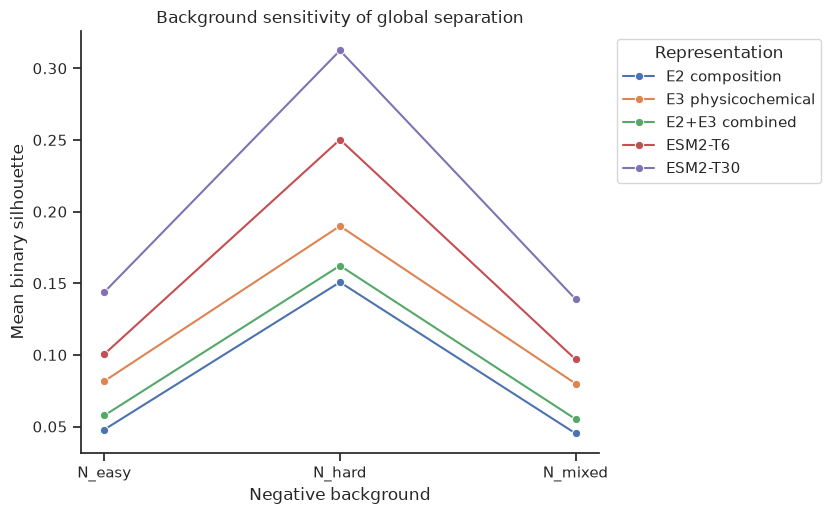

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E6/figures/E6_background_knn25.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E6/figures/E6_background_knn25.pdf


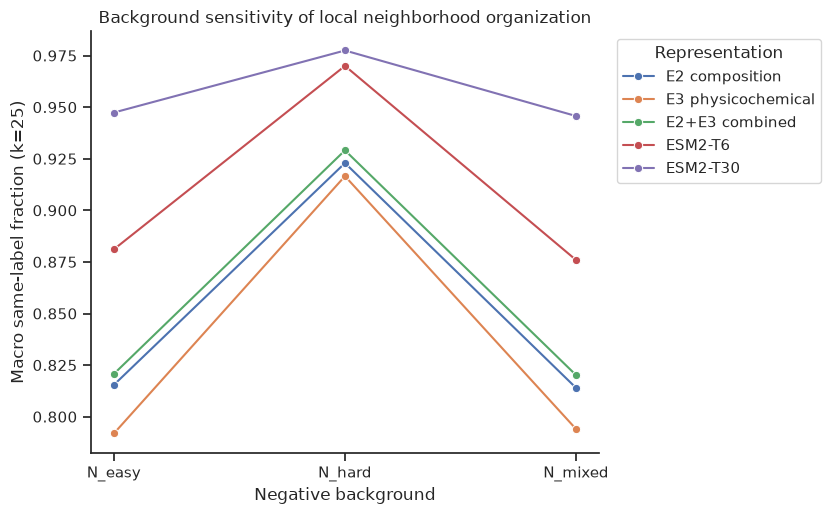

In [17]:
BACKGROUND_ORDER = [
    "N_easy",
    "N_mixed",
    "N_hard",
]

REP_ORDER = [
    "E2_all",
    "E3_all",
    "E2_E3_all",
    "esm2_t6",
    "esm2_t30",
]

REP_DISPLAY_ORDER = [
    REPRESENTATIONS[
        rep
    ]["display_name"]
    for rep in REP_ORDER
]


# ---------------------------------------------------------------
# Figure 1 — silhouette by background
# ---------------------------------------------------------------
plot_df = background_summary.loc[
    background_summary[
        "metric"
    ].eq("silhouette")
    & background_summary[
        "group"
    ].fillna("").eq("")
].copy()

fig, ax = plt.subplots(
    figsize=(8.5, 5.3)
)

sns.lineplot(
    data=plot_df,
    x="background",
    y="mean",
    hue="display_name",
    hue_order=REP_DISPLAY_ORDER,
    marker="o",
    sort=False,
    ax=ax,
)

ax.set_xlabel(
    "Negative background"
)
ax.set_ylabel(
    "Mean binary silhouette"
)
ax.set_title(
    "Background sensitivity of global separation"
)
ax.legend(
    title="Representation",
    bbox_to_anchor=(
        1.02,
        1.0,
    ),
    loc="upper left",
)

sns.despine()
fig.tight_layout()

save_figure(
    fig,
    "E6_background_silhouette",
)

plt.show()


# ---------------------------------------------------------------
# Figure 2 — macro kNN purity by background
# ---------------------------------------------------------------
plot_df = background_summary.loc[
    background_summary[
        "metric"
    ].eq(
        "macro_same_label_knn_fraction"
    )
].copy()

fig, ax = plt.subplots(
    figsize=(8.5, 5.3)
)

sns.lineplot(
    data=plot_df,
    x="background",
    y="mean",
    hue="display_name",
    hue_order=REP_DISPLAY_ORDER,
    marker="o",
    sort=False,
    ax=ax,
)

ax.set_xlabel(
    "Negative background"
)
ax.set_ylabel(
    f"Macro same-label fraction (k={K})"
)
ax.set_title(
    "Background sensitivity of local neighborhood organization"
)
ax.legend(
    title="Representation",
    bbox_to_anchor=(
        1.02,
        1.0,
    ),
    loc="upper left",
)

sns.despine()
fig.tight_layout()

save_figure(
    fig,
    "E6_background_knn25",
)

plt.show()

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E6/figures/E6_background_rank_silhouette.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E6/figures/E6_background_rank_silhouette.pdf


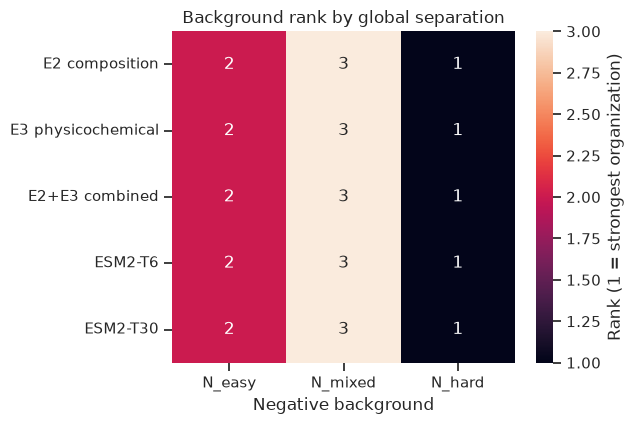

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E6/figures/E6_background_rank_knn25.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E6/figures/E6_background_rank_knn25.pdf


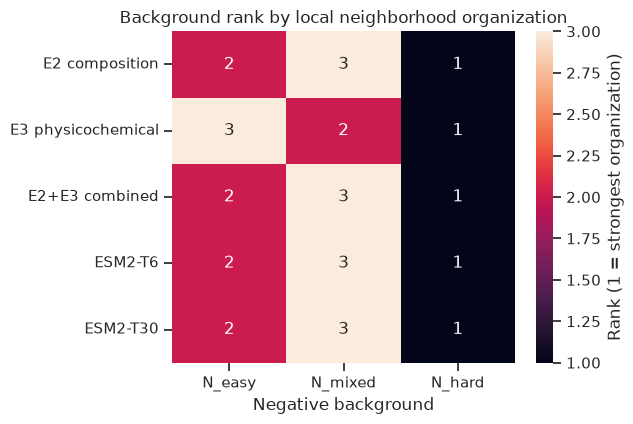

In [18]:
# ---------------------------------------------------------------
# Figure 3 — background ranks
# ---------------------------------------------------------------
for metric, title, stem in [
    (
        "silhouette",
        "Background rank by global separation",
        "E6_background_rank_silhouette",
    ),
    (
        "macro_same_label_knn_fraction",
        "Background rank by local neighborhood organization",
        "E6_background_rank_knn25",
    ),
]:
    matrix = (
        background_rankings.loc[
            background_rankings[
                "metric"
            ].eq(metric)
        ]
        .pivot(
            index="display_name",
            columns="background",
            values="background_rank",
        )
        .reindex(
            index=REP_DISPLAY_ORDER,
            columns=BACKGROUND_ORDER,
        )
    )

    fig, ax = plt.subplots(
        figsize=(6.4, 4.4)
    )

    sns.heatmap(
        matrix,
        annot=True,
        fmt=".0f",
        cbar_kws={
            "label": "Rank (1 = strongest organization)"
        },
        ax=ax,
    )

    ax.set_xlabel(
        "Negative background"
    )
    ax.set_ylabel("")
    ax.set_title(title)

    fig.tight_layout()

    save_figure(
        fig,
        stem,
    )

    plt.show()

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E6/figures/E6_geometry_agreement.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E6/figures/E6_geometry_agreement.pdf


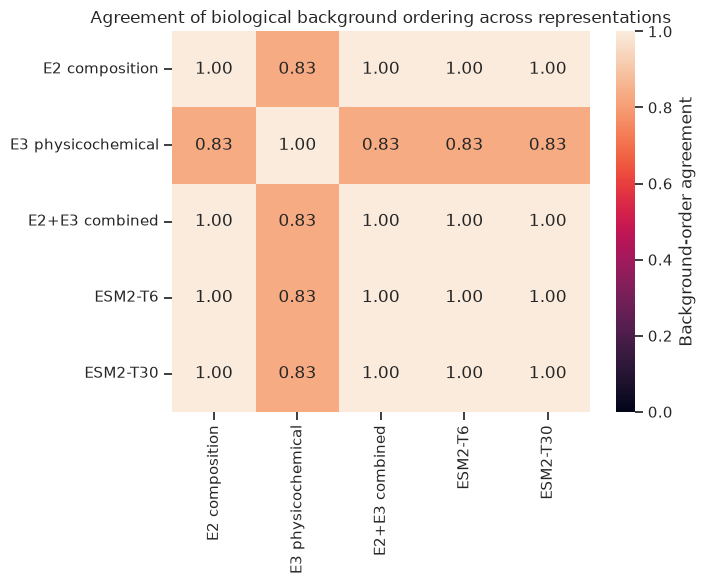

In [19]:
# ---------------------------------------------------------------
# Figure 4 — representation agreement matrix
# ---------------------------------------------------------------
combined_agreement = geometry_agreement.loc[
    geometry_agreement[
        "metric"
    ].eq(
        "combined_primary_metrics"
    )
].copy()

agreement_matrix = pd.DataFrame(
    np.eye(
        len(REP_ORDER),
        dtype=float,
    ),
    index=REP_ORDER,
    columns=REP_ORDER,
)

for row in combined_agreement.itertuples():
    agreement_matrix.loc[
        row.representation_a,
        row.representation_b,
    ] = row.agreement_fraction

    agreement_matrix.loc[
        row.representation_b,
        row.representation_a,
    ] = row.agreement_fraction

agreement_matrix.index = [
    REPRESENTATIONS[
        rep
    ]["display_name"]
    for rep in agreement_matrix.index
]

agreement_matrix.columns = [
    REPRESENTATIONS[
        rep
    ]["display_name"]
    for rep in agreement_matrix.columns
]


fig, ax = plt.subplots(
    figsize=(7.2, 6.0)
)

sns.heatmap(
    agreement_matrix,
    vmin=0,
    vmax=1,
    annot=True,
    fmt=".2f",
    cbar_kws={
        "label": "Background-order agreement"
    },
    ax=ax,
)

ax.set_title(
    "Agreement of biological background ordering across representations"
)
ax.set_xlabel("")
ax.set_ylabel("")

fig.tight_layout()

save_figure(
    fig,
    "E6_geometry_agreement",
)

plt.show()

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E6/figures/E6_subtype_knn25_consistency.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E6/figures/E6_subtype_knn25_consistency.pdf


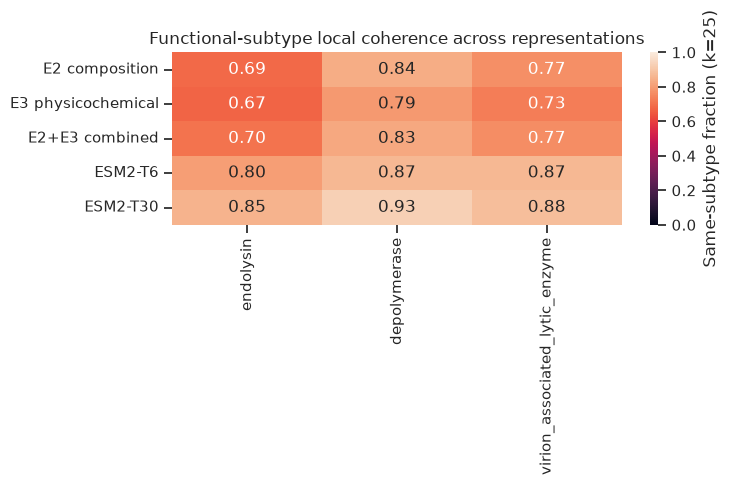

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E6/figures/E6_subtype_dispersion_rank.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E6/figures/E6_subtype_dispersion_rank.pdf


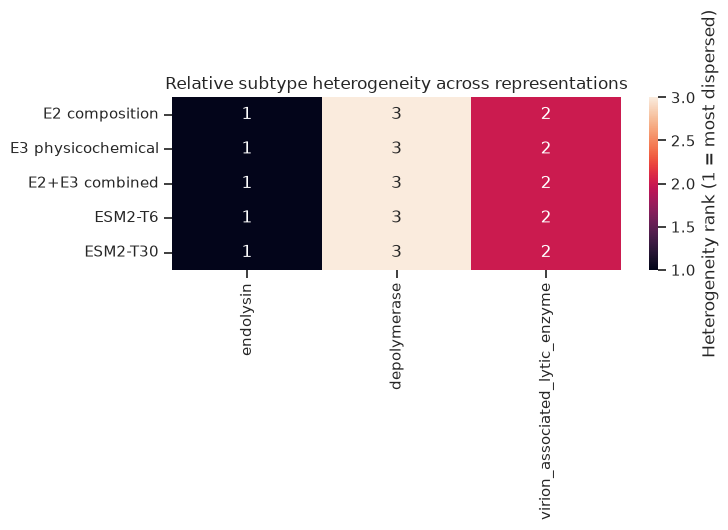

In [20]:
# ---------------------------------------------------------------
# Figure 5 — same-subtype local coherence at k=25
# ---------------------------------------------------------------
subtype_knn = subtype_consistency.loc[
    subtype_consistency[
        "metric"
    ].eq(
        "same_subtype_knn_fraction"
    )
].copy()

subtype_knn_matrix = (
    subtype_knn
    .pivot(
        index="display_name",
        columns="subtype",
        values="value",
    )
    .reindex(
        index=REP_DISPLAY_ORDER,
        columns=SUBTYPES,
    )
)


fig, ax = plt.subplots(
    figsize=(7.6, 4.8)
)

sns.heatmap(
    subtype_knn_matrix,
    annot=True,
    fmt=".2f",
    vmin=0,
    vmax=1,
    cbar_kws={
        "label": f"Same-subtype fraction (k={K})"
    },
    ax=ax,
)

ax.set_title(
    "Functional-subtype local coherence across representations"
)
ax.set_xlabel("")
ax.set_ylabel("")

fig.tight_layout()

save_figure(
    fig,
    "E6_subtype_knn25_consistency",
)

plt.show()


# ---------------------------------------------------------------
# Figure 6 — subtype heterogeneity ranks
# ---------------------------------------------------------------
dispersion_rank_matrix = (
    subtype_consistency.loc[
        subtype_consistency[
            "metric"
        ].eq(
            "within_subtype_dispersion"
        )
    ]
    .pivot(
        index="display_name",
        columns="subtype",
        values="within_representation_rank",
    )
    .reindex(
        index=REP_DISPLAY_ORDER,
        columns=SUBTYPES,
    )
)


fig, ax = plt.subplots(
    figsize=(7.6, 4.8)
)

sns.heatmap(
    dispersion_rank_matrix,
    annot=True,
    fmt=".0f",
    cbar_kws={
        "label": "Heterogeneity rank (1 = most dispersed)"
    },
    ax=ax,
)

ax.set_title(
    "Relative subtype heterogeneity across representations"
)
ax.set_xlabel("")
ax.set_ylabel("")

fig.tight_layout()

save_figure(
    fig,
    "E6_subtype_dispersion_rank",
)

plt.show()

## 15. Final closure audit

In [21]:
assert REDUNDANCY_ANALYSIS_DISABLED is True
assert EMBEDDING_GENERATION_DISABLED is True

assert len(common_labels) == 434_768
assert len(E2_FEATURES) == 71
assert len(E3_FEATURES) == 27

assert set(
    REPRESENTATIONS
) == {
    "E2_all",
    "E3_all",
    "E2_E3_all",
    "esm2_t6",
    "esm2_t30",
}

assert set(
    background_summary[
        "background"
    ]
) == {
    "N_easy",
    "N_hard",
    "N_mixed",
}

assert set(
    background_rankings[
        "metric"
    ]
) == set(
    PRIMARY_METRICS
)

assert set(
    subtype_consistency[
        "representation"
    ]
) == set(
    REPRESENTATIONS
)

assert set(
    subtype_consistency.loc[
        subtype_consistency[
            "subtype"
        ].fillna("").ne(""),
        "subtype",
    ]
) == set(
    SUBTYPES
)


# Exactly 5 representations × 3 backgrounds for each primary ranking metric.
ranking_counts = (
    background_rankings
    .groupby(
        "metric"
    )
    .size()
)

for metric in PRIMARY_METRICS:
    if ranking_counts[
        metric
    ] != 15:
        raise RuntimeError(
            f"{metric}: expected 15 ranking rows."
        )


# Each representation/background/metric summary must contain all repeats.
repeat_audit = background_summary[
    "n_repeats"
].unique()

if set(repeat_audit) != {
    BACKGROUND_REPEATS
}:
    raise RuntimeError(
        f"Unexpected repeat counts in background summary: {repeat_audit}"
    )


required_outputs = [
    BACKGROUND_REPEATS_PATH,
    BACKGROUND_SUMMARY_PATH,
    BACKGROUND_RANKINGS_PATH,
    CONSISTENCY_PATH,
    GEOMETRY_AGREEMENT_PATH,
    REP_SPECIFIC_PATH,
    SUBTYPE_CONSISTENCY_PATH,
    SUBTYPE_PATTERN_PATH,
    SAMPLE_MANIFEST_PATH,
]

for path in required_outputs:
    if not path.is_file():
        raise RuntimeError(
            f"Missing E6 output: {path}"
        )


metadata = {
    "stage": "E6",
    "scientific_question": (
        "Which conclusions about the phage-lytic space remain stable "
        "when the negative background and the representation are changed?"
    ),
    "representations": {
        rep: REPRESENTATIONS[
            rep
        ]
        for rep in REPRESENTATIONS
    },
    "common_universe_rows": int(
        len(common_labels)
    ),
    "backgrounds": [
        "N_easy",
        "N_hard",
        "N_mixed",
    ],
    "background_repeats": BACKGROUND_REPEATS,
    "n_per_class": N_PER_CLASS,
    "knn_k": K,
    "explicit_geometry": (
        "StandardScaler fit on the common PLM universe; "
        "Euclidean distance."
    ),
    "plm_geometry": (
        "Frozen pooled embeddings; cosine distance."
    ),
    "primary_consistency_metrics": PRIMARY_METRICS,
    "geometry_agreement_definition": (
        "Agreement in pairwise ordering of negative backgrounds across "
        "silhouette and macro same-label kNN metrics; not direct geometric equivalence."
    ),
    "subtype_results_source": {
        "explicit": "Frozen E4 summaries",
        "learned": "Frozen E5_v2 summaries",
    },
    "embedding_generation_disabled": True,
    "redundancy_analysis_disabled": True,
    "redundancy_analysis_deferred_to": "E7",
    "random_seed": RANDOM_SEED,
}


METADATA_PATH.write_text(
    json.dumps(
        metadata,
        indent=2,
    ),
    encoding="utf-8",
)


print("=" * 78)
print(
    "PASS — E6 cross-representation and background consistency completed."
)
print("=" * 78)
print()
print(
    "No embeddings were generated."
)
print(
    "No redundancy threshold was introduced; redundancy sensitivity remains E7."
)
print(
    "Direct point-by-point geometric equivalence was not tested."
)
print()
print(f"Results: {RESULT_DIR}")

PASS — E6 cross-representation and background consistency completed.

No embeddings were generated.
No redundancy threshold was introduced; redundancy sensitivity remains E7.
Direct point-by-point geometric equivalence was not tested.

Results: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E6
